# SSA channel

Walks through the channel of **mi-race** one piece at a time, and checks the simulation against exact theory.

```text
symbol k ──► encoder ──► release schedule ──► SSA channel ──► receiver signal rx ──► decoder (step 5)
```

Every result comes from the package code in `src/mi_race/`. The notebook adds no physics of its own, except the exact formula in section 7 that is used to check the simulation.

*To run it: use the project's virtual environment as the kernel (it needs `mi_race`, `matplotlib` and `scipy`), then Run All.*

In [1]:
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import expm

from mi_race.config import load_config
from mi_race.encoder import release_schedule
from mi_race.channel import jump_rates, next_jump, simulate, snapshot_times, receiver_signal, transmit

cfg = load_config(Path("..") / "configs" / "example.json")
ch, enc = cfg.channel, cfg.encoder
rng = np.random.default_rng(cfg.seed)                   # one random generator for the whole notebook

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # one fixed colour per symbol
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False,
})

## 1. The experiment

Everything comes from one checked config file, `configs/example.json`.

In [2]:
print(f"tube:     L = {ch.L} positions: compartments 0 ... {ch.L - 2}, receiver at {ch.L - 1}")
print(f"physics:  h = {ch.h}, D = {ch.D}  ->  jump rate λ = D / h² = {ch.jump_rate} per second")
print(f"time:     T = {ch.T} s, a snapshot every dt = {ch.dt} s  ->  M = {ch.n_intervals} intervals")
print(f"encoder:  {enc.n_slots} slots of {enc.slot_dt} s, budget {enc.budget} molecules, {enc.n_symbols} symbols")
for k, vector in enumerate(enc.symbols):
    print(f"  symbol {k}: {vector}")

tube:     L = 4 positions: compartments 0 ... 2, receiver at 3
physics:  h = 1.0, D = 2.0  ->  jump rate λ = D / h² = 2.0 per second
time:     T = 2.0 s, a snapshot every dt = 0.01 s  ->  M = 200 intervals
encoder:  10 slots of 0.1 s, budget 50 molecules, 4 symbols
  symbol 0: (50, 0, 0, 0, 0, 0, 0, 0, 0, 0)
  symbol 1: (0, 0, 0, 50, 0, 0, 0, 0, 0, 0)
  symbol 2: (0, 0, 0, 0, 0, 0, 50, 0, 0, 0)
  symbol 3: (0, 0, 0, 0, 0, 0, 0, 0, 0, 50)


## 2. Encoder: symbol → release schedule

A symbol is a **release vector over time slots**. Entry *k* is the number of molecules released at *t* = *k* · `slot_dt`. Every release goes into compartment 0, so the example symbols differ only in **when** the molecules are released.

In [3]:
schedules = [release_schedule(vector, enc.slot_dt) for vector in enc.symbols]
for k, schedule in enumerate(schedules):
    print(f"symbol {k}: {schedule}      (time in s, molecules)")

symbol 0: [(0.0, 50)]      (time in s, molecules)
symbol 1: [(0.3, 50)]      (time in s, molecules)
symbol 2: [(0.6, 50)]      (time in s, molecules)
symbol 3: [(0.9, 50)]      (time in s, molecules)


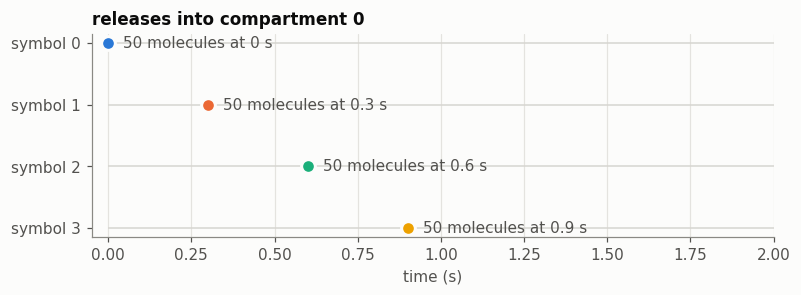

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.4))
for k, schedule in enumerate(schedules):
    ax.hlines(k, 0, ch.T, color="#d6d5d0", linewidth=1)
    for t, amount in schedule:
        ax.plot(t, k, "o", markersize=9, color=COLORS[k], markeredgecolor="#fcfcfb", markeredgewidth=2)
        ax.annotate(f"{amount} molecules at {t:g} s", (t, k), xytext=(10, 0), textcoords="offset points",
                    va="center", color=MUTED)
ax.set(title="releases into compartment 0", xlabel="time (s)", xlim=(-0.05, ch.T),
       yticks=range(enc.n_symbols), yticklabels=[f"symbol {k}" for k in range(enc.n_symbols)])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
plt.show()

- There is one row per symbol. The grey line is the observation window, from 0 to T = 2 s.
- The dot marks **when** the symbol releases its molecules, and the label says how many.
- All four symbols release the same 50 molecules into compartment 0. Only the release time differs, by 0.3 s from one symbol to the next, so the information is carried by **timing alone**.
- Symbol 3 releases at 0.9 s, which leaves its molecules only 1.1 s to reach the receiver before T.

## 3. The channel: what can happen next

```text
 wall │ comp 0 │ comp 1 │ comp 2 │ receiver (position 3)
      │  ◄─ ─► │  ◄─ ─► │  ◄─ ─► │──► absorbed, counted in rx
```

Each molecule jumps to each neighbour at rate λ. A compartment holding *n* molecules therefore sends molecules each way at rate λ·n. Compartment 0 has a reflecting wall on its left, and a jump into the receiver is an absorption. The SSA lists every jump that is possible right now, together with its rate:

In [5]:
counts = [30, 15, 5]
jumps = jump_rates(counts, ch.jump_rate)
total = sum(rate for _, _, rate in jumps)
print(f"counts {counts}: total rate {total:g} per second  ->  mean wait {1000 / total:.1f} ms\n")
print("  jump                  rate   chance to be next")
for source, target, rate in jumps:
    name = "receiver" if target == ch.L - 1 else f"comp {target}"
    print(f"  comp {source} -> {name:9s}  {rate:5g}   {rate / total:.3f}")

counts [30, 15, 5]: total rate 140 per second  ->  mean wait 7.1 ms

  jump                  rate   chance to be next
  comp 0 -> comp 1        60   0.429
  comp 1 -> comp 0        30   0.214
  comp 1 -> comp 2        30   0.214
  comp 2 -> comp 1        10   0.071
  comp 2 -> receiver      10   0.071


## 4. One SSA event: when, and which jump?

The wait until the next jump is **exponential** with mean 1 / total rate. The jump itself is picked with probability rate / total. Here are 20,000 draws from the state above:

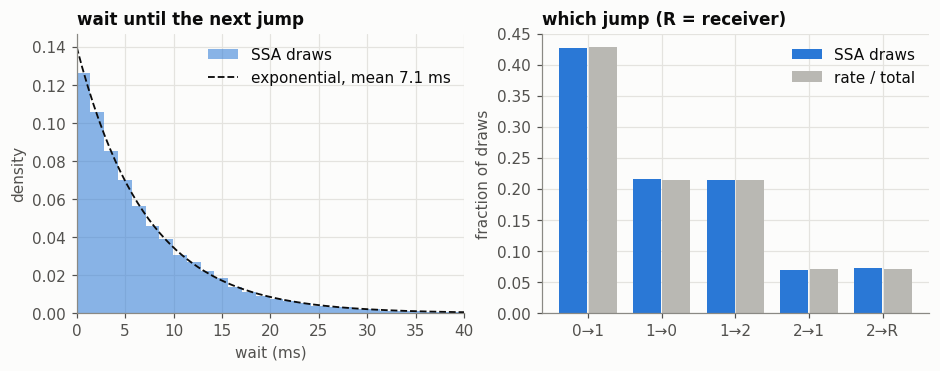

In [6]:
draws = [next_jump(jumps, rng) for _ in range(20_000)]
waits = np.array([wait for wait, _, _ in draws])
picked = [(source, target) for _, source, target in draws]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.3))
left.hist(waits * 1000, bins=60, density=True, color=COLORS[0], alpha=0.55, label="SSA draws")
t = np.linspace(0, waits.max(), 300)
left.plot(t * 1000, total * np.exp(-total * t) / 1000, color=INK, linewidth=1.2, linestyle="--",
          label=f"exponential, mean {1000 / total:.1f} ms")
left.set(title="wait until the next jump", xlabel="wait (ms)", ylabel="density", xlim=(0, 40))
left.legend()

x = np.arange(len(jumps))
names = [f"{s}→{'R' if d == ch.L - 1 else d}" for s, d, _ in jumps]
right.bar(x - 0.2, [picked.count((s, d)) / len(picked) for s, d, _ in jumps], width=0.38,
          color=COLORS[0], label="SSA draws")
right.bar(x + 0.2, [rate / total for _, _, rate in jumps], width=0.38, color="#b9b8b3", label="rate / total")
right.set(title="which jump (R = receiver)", xticks=x, xticklabels=names, ylabel="fraction of draws")
right.legend()
plt.show()

- **Left:** the 20,000 sampled waits as a histogram (blue), with the exponential curve they should follow (dashed). Short waits are the most common and long ones are increasingly rare. The bars follow the curve, and the average wait is 1/140 s ≈ 7.1 ms.
- **Right:** for each possible jump, how often it was picked (blue), next to its rate / total (grey). Each pair has the same height. For example, `0→1` is picked about 43 % of the time, because compartment 0 holds the most molecules (30 × λ = 60 of the total 140 per second).
- Together, the two panels show that `next_jump` draws both the **time** and the **choice** of the next event with the right probabilities. That is what makes the SSA exact rather than approximate.

## 5. One full run

`simulate` repeats that event, moving one molecule per jump, and inserts each release at its exact time.

If a sampled jump would come after the next release, it is **discarded**: the clock moves to the release, the molecules are added, and new rates are drawn. This is exact, because waiting times are memoryless. When the tube is empty, time skips straight to the next release.

The run returns the time of every absorption. Their running count, $A(t)$, is a staircase:

symbol 0: released 50, absorbed 23, still in the tube [17, 5, 5]  ->  conservation ok
symbol 1: released 50, absorbed 21, still in the tube [9, 9, 11]  ->  conservation ok
symbol 2: released 50, absorbed 15, still in the tube [15, 10, 10]  ->  conservation ok
symbol 3: released 50, absorbed 12, still in the tube [14, 17, 7]  ->  conservation ok


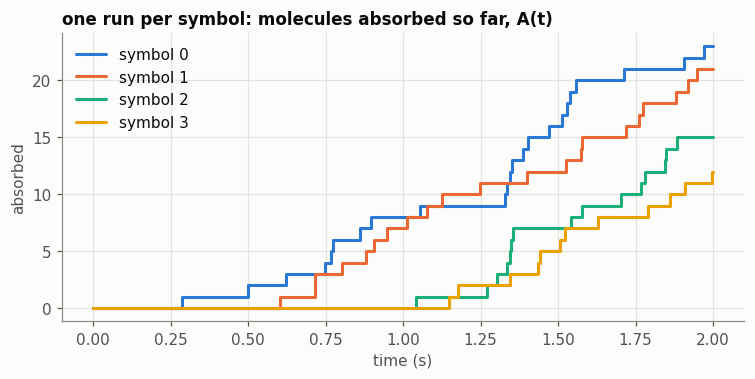

In [7]:
snapshots = snapshot_times(ch.dt, ch.n_intervals)        # t_0 ... t_M
fig, ax = plt.subplots(figsize=(8, 3.4))
for k, schedule in enumerate(schedules):
    absorbed, counts = simulate(schedule, ch.L, ch.jump_rate, snapshots[-1], rng)
    released = sum(amount for _, amount in schedule)
    ok = len(absorbed) + sum(counts) == released
    print(f"symbol {k}: released {released}, absorbed {len(absorbed):2d}, still in the tube {counts}"
          f"  ->  conservation {'ok' if ok else 'BROKEN'}")
    ax.step([0] + absorbed + [ch.T], [0, *range(1, len(absorbed) + 1), len(absorbed)], where="post",
            color=COLORS[k], label=f"symbol {k}")
ax.set(title="one run per symbol: molecules absorbed so far, A(t)", xlabel="time (s)", ylabel="absorbed")
ax.legend(loc="upper left")
plt.show()

- x is time and y is the number of molecules absorbed so far, $A(t)$. Each step up is one molecule reaching the receiver.
- Every line stays flat for a while after its release. A molecule needs at least 3 jumps (comp 0 → 1 → 2 → receiver) to arrive, so there is always a **travel delay**.
- A later release starts later and ends lower, because its molecules have less time before T.
- This is a single random run per symbol, so the staircases change each time the cell is run. The printed lines check conservation for each run: released = still in the tube + absorbed.

## 6. Receiver signal

The receiver reports how many molecules arrived in each interval:

$$rx_0 = 0, \qquad rx_m = A(t_m) - A(t_{m-1}) \quad \text{(absorptions in } (t_{m-1}, t_m]\text{)}, \quad m = 1 \dots M$$

So one run of one symbol gives $M + 1 = 201$ numbers. That is one row of the dataset, and it is what the decoders will read. Here is one run per symbol (the dashed line marks the release):

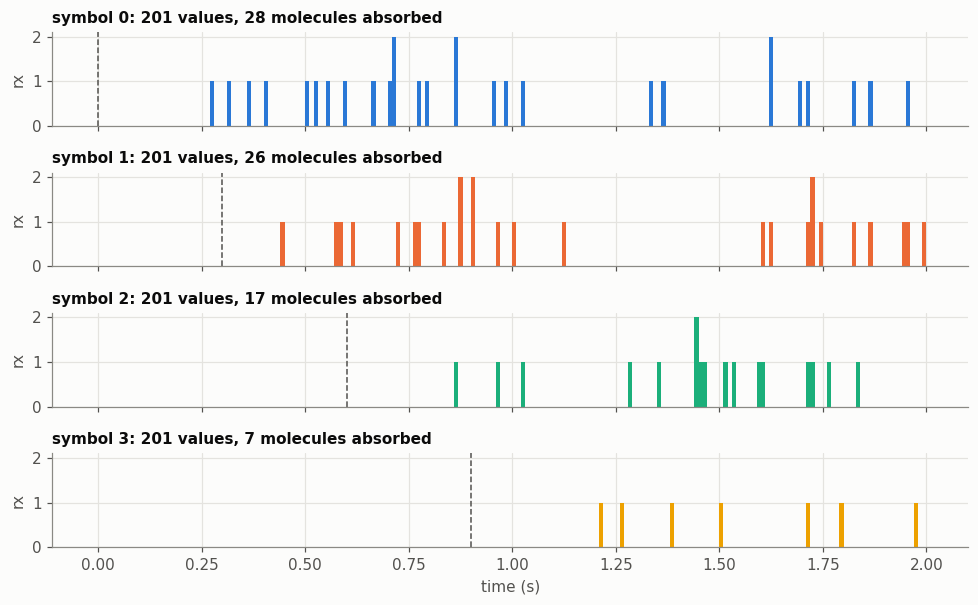

In [ ]:
fig, axes = plt.subplots(enc.n_symbols, 1, figsize=(9, 5.6), sharex=True, sharey=True)
for k, (vector, schedule, ax) in enumerate(zip(enc.symbols, schedules, axes)):
    rx = transmit(vector, cfg, rng)
    ax.bar(np.array(snapshots) - ch.dt, rx, width=ch.dt, align="edge", color=COLORS[k])
    for t, _ in schedule:
        ax.axvline(t, color=MUTED, linewidth=1, linestyle="--")
    ax.set_title(f"symbol {k}: {len(rx)} values, {sum(rx)} molecules absorbed", fontsize=10)
    ax.set_ylabel("rx")
axes[-1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

- There is one panel per symbol, with one run each. Each bar is one 0.01 s interval, and its height is $rx_m$, the number of molecules absorbed in that interval. It is mostly 0, sometimes 1, and rarely 2.
- The dashed line is the release time. The empty gap after it is the travel delay from §5.
- This is exactly what a decoder receives: 201 small, noisy counts. It has to recognise the symbol from **where** the arrivals start and **how many** there are.
- These are new runs, so the numbers differ from §5.

## 7. Many runs, checked against exact theory

The molecules move **independently**, so the chance that one molecule, released into compartment 0 at time *s*, has been absorbed by time *t* can be computed exactly:

$$P(t - s) = 1 - \big[e^{Q\,(t-s)}\,\mathbf{1}\big]_0$$

Here $Q$ is the $(L-1)\times(L-1)$ matrix of jump rates between the compartments. The receiver is left out of $Q$, because leaving the compartments means being absorbed.

The mean of $A(t)$ is then $\sum_j n_j\, P(t - s_j)$, summed over the releases. Below, this is compared with 300 simulated runs per symbol, the same number the dataset will use.

In [9]:
def absorbed_probability(t, L, jump_rate):
    # exact chance that one molecule released into compartment 0 is absorbed after time t
    if t <= 0:
        return 0.0
    n = L - 1                                           # compartments 0 ... L-2
    Q = np.zeros((n, n))
    for i in range(n):
        if i > 0:
            Q[i, i - 1] = jump_rate                     # left
        if i < n - 1:
            Q[i, i + 1] = jump_rate                     # right, into the next compartment
        Q[i, i] = -jump_rate * (2 if i > 0 else 1)      # leaving i (comp 0: right only, wall on the left)
    return 1 - (expm(Q * t) @ np.ones(n))[0]


def mean_absorbed(schedule, times, L, jump_rate):
    # exact mean of A(t): every molecule counts with its own chance
    return np.array([sum(amount * absorbed_probability(t - s, L, jump_rate) for s, amount in schedule)
                     for t in times])


RUNS = cfg.data.runs_per_symbol
signals = np.array([[transmit(vector, cfg, rng) for _ in range(RUNS)] for vector in enc.symbols])
print("signals:", signals.shape, "= (symbols, runs, snapshots)")

signals: (4, 300, 201) = (symbols, runs, snapshots)


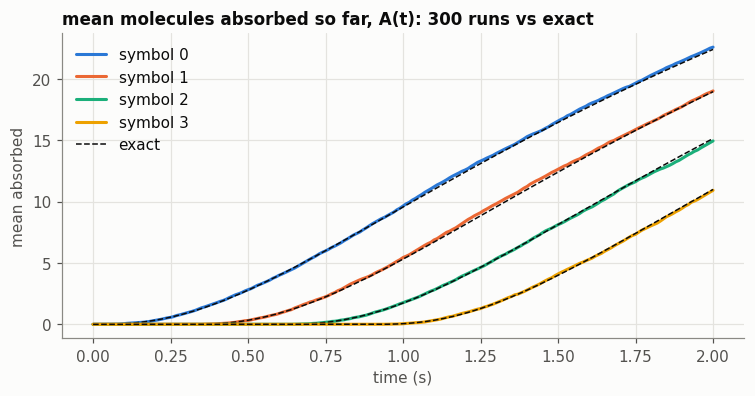

symbol   mean A(T), simulated     exact
  0        22.58 ± 0.20           22.40
  1        19.01 ± 0.21           18.95
  2        14.94 ± 0.17           15.13
  3        10.92 ± 0.16           10.99


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, schedule in enumerate(schedules):
    ax.plot(snapshots, signals[k].cumsum(axis=1).mean(axis=0), color=COLORS[k], label=f"symbol {k}")
    ax.plot(snapshots, mean_absorbed(schedule, snapshots, ch.L, ch.jump_rate),
            color=INK, linewidth=1, linestyle="--")
ax.plot([], [], color=INK, linewidth=1, linestyle="--", label="exact")
ax.set(title=f"mean molecules absorbed so far, A(t): {RUNS} runs vs exact", xlabel="time (s)",
       ylabel="mean absorbed")
ax.legend(loc="upper left")
plt.show()

print("symbol   mean A(T), simulated     exact")
for k, schedule in enumerate(schedules):
    totals = signals[k].sum(axis=1)
    exact = mean_absorbed(schedule, [snapshots[-1]], ch.L, ch.jump_rate)[0]
    print(f"  {k}        {totals.mean():5.2f} ± {totals.std(ddof=1) / np.sqrt(RUNS):.2f}           {exact:5.2f}")

**How to read this plot and the table**
- Each coloured line is $A(t)$ averaged over 300 runs. The black dashed line under it is the exact mean from the formula above.
- For all four symbols, the coloured line lies on the dashed one, from the first arrivals up to T. So the SSA is right on average.
- The table makes the same check at t = T: the simulated mean ± its standard error, next to the exact value. Every difference is within about one standard error, which is the size random noise alone produces.
- The curves stay far below 50. With λ = 2 per second and 3 compartments, a molecule needs **3 s** on average to reach the receiver (exactly: $\mathbf{e}_0^\top(-Q)^{-1}\mathbf{1} = 3$ s). That is longer than the 2 s window, so fewer than half of the molecules arrive in time, even for the earliest symbol.

The mean signal itself, $\overline{rx}_m$, is the shape the decoders will learn to tell apart. Per interval it is noisy with 300 runs, but it follows the exact curve, which is the difference of the curve above:

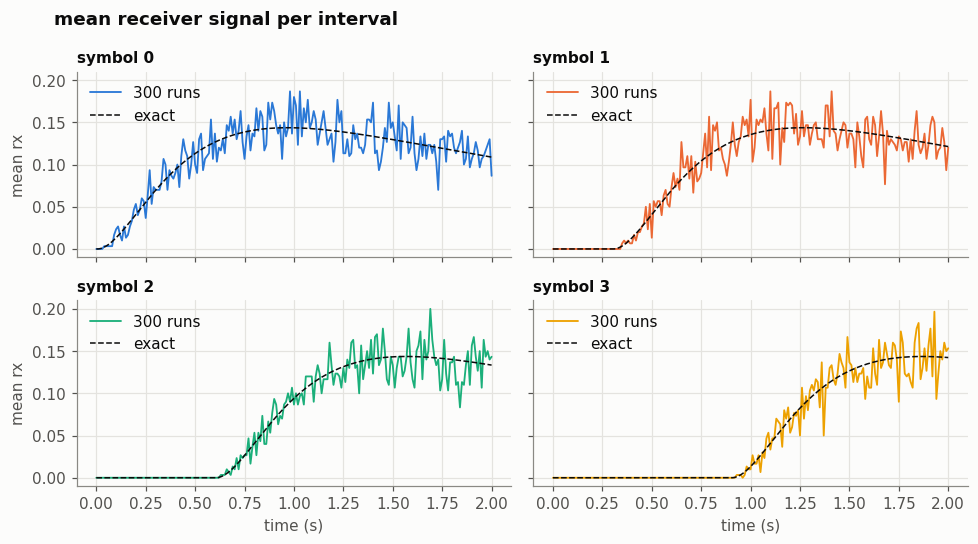

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5), sharex=True, sharey=True)
for k, (schedule, ax) in enumerate(zip(schedules, axes.flat)):
    exact = np.diff(mean_absorbed(schedule, snapshots, ch.L, ch.jump_rate), prepend=0.0)
    ax.plot(snapshots, signals[k].mean(axis=0), color=COLORS[k], linewidth=1.2, label=f"{RUNS} runs")
    ax.plot(snapshots, exact, color=INK, linewidth=1, linestyle="--", label="exact")
    ax.set_title(f"symbol {k}", fontsize=10)
    ax.legend(loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("mean rx")
fig.suptitle("mean receiver signal per interval", x=0.06, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**How to read this plot**
- There is one panel per symbol. The coloured line is the mean of $rx_m$ over 300 runs, and the dashed line is the exact expected count per interval.
- It looks noisy because each 0.01 s interval receives only about 0.1 molecule on average, and 300 runs are not enough to smooth that out. The line still scatters evenly around the exact curve.
- All four symbols have the **same shape**, shifted by their release time: zero during the travel delay, then a rise, a peak of about 0.14 molecules per interval, and a slow decline. This shape is the channel's response to one pulse.
- T cuts the later symbols short. Symbol 3 only reaches its peak at the very end, so the decoder never sees most of its response.

## 8. Not only the mean: the whole distribution

Each molecule released at time $s_j$ is absorbed by $T$ independently, with the same chance $p_j = P(T - s_j)$. So every release adds a $\text{Binomial}(n_j, p_j)$ count, and the exact distribution of $A(T)$ is the convolution of these (just one binomial for the example symbols):

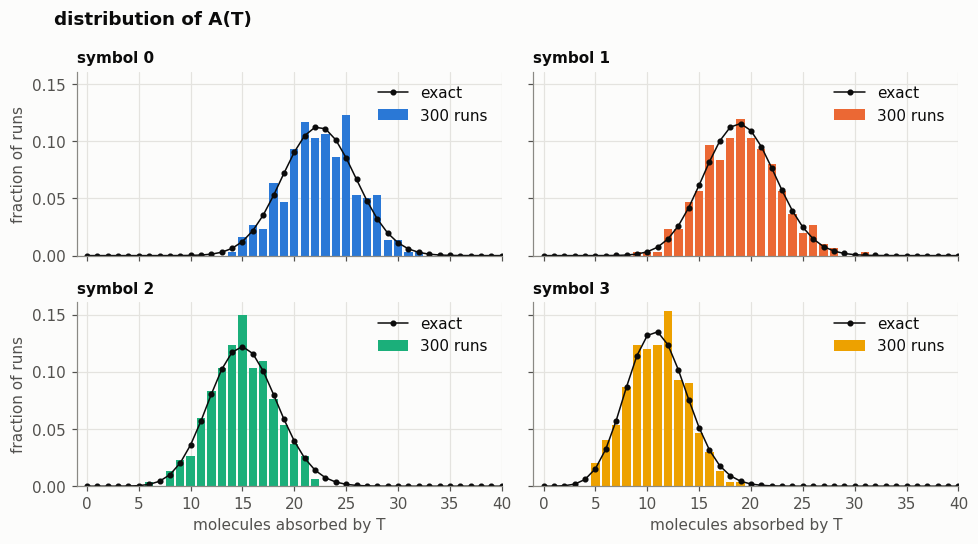

In [12]:
def absorbed_distribution(schedule, t, L, jump_rate):
    # exact distribution of A(t): each release adds an independent Binomial(n, p) count
    pmf = np.array([1.0])
    for s, amount in schedule:
        p = absorbed_probability(t - s, L, jump_rate)
        pmf = np.convolve(pmf, [comb(amount, j) * p**j * (1 - p)**(amount - j) for j in range(amount + 1)])
    return pmf


fig, axes = plt.subplots(2, 2, figsize=(9, 5), sharex=True, sharey=True)
for k, (schedule, ax) in enumerate(zip(schedules, axes.flat)):
    totals = signals[k].sum(axis=1)
    values = np.arange(enc.budget + 1)
    simulated = np.bincount(totals, minlength=enc.budget + 1) / RUNS
    ax.bar(values, simulated, width=0.8, color=COLORS[k], label=f"{RUNS} runs")
    ax.plot(values, absorbed_distribution(schedule, snapshots[-1], ch.L, ch.jump_rate), "o-",
            color=INK, linewidth=1, markersize=3, label="exact")
    ax.set_title(f"symbol {k}", fontsize=10)
    ax.legend(loc="upper right")
for ax in axes[1]:
    ax.set_xlabel("molecules absorbed by T")
for ax in axes[:, 0]:
    ax.set_ylabel("fraction of runs")
ax.set_xlim(-1, 40)
fig.suptitle("distribution of A(T)", x=0.06, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**How to read this plot**
- There is one panel per symbol. Each bar is the fraction of the 300 runs in which exactly that many molecules were absorbed by T. The black dots are the exact binomial probabilities.
- The bars follow the dots. Single bars stick out a little, which is normal sampling noise with 300 runs. So the SSA gets the **run-to-run randomness** right, not only the average.
- This matters for decoding, because that spread is the noise the decoders must cope with. The standard deviation is about 3 to 3.5 molecules, depending on the symbol.
- An earlier release shifts the whole distribution to the right.

## 9. Can the symbols be told apart?

A decoder will see one signal and has to guess which symbol was sent. Two simple features of the 300 runs per symbol give a first idea of how hard that is: **how many** molecules arrived, and **when the first one** arrived.

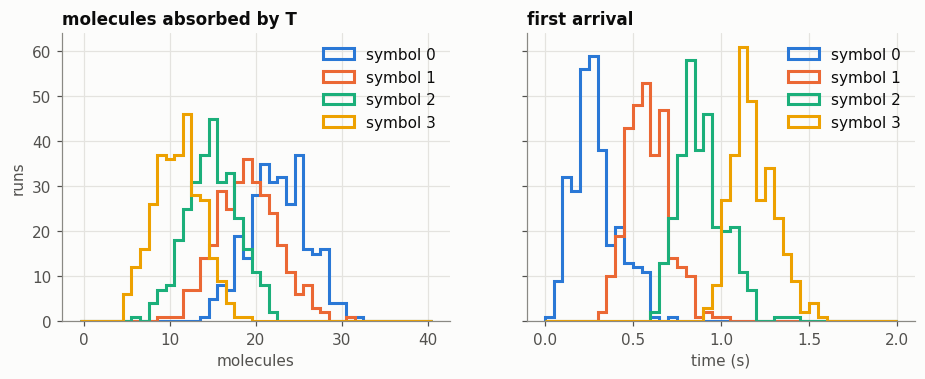

In [13]:
first_arrival = [[snapshots[np.argmax(row > 0)] for row in signals[k] if row.any()] for k in range(enc.n_symbols)]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for k in range(enc.n_symbols):
    left.hist(signals[k].sum(axis=1), bins=np.arange(-0.5, 41), histtype="step", linewidth=2,
              color=COLORS[k], label=f"symbol {k}")
    right.hist(first_arrival[k], bins=np.arange(0, ch.T + 0.05, 0.05), histtype="step", linewidth=2,
               color=COLORS[k], label=f"symbol {k}")
left.set(title="molecules absorbed by T", xlabel="molecules", ylabel="runs")
right.set(title="first arrival", xlabel="time (s)")
left.legend()
right.legend()
plt.show()

**How to read this plot**
- **Left:** how many runs ended with a given number of molecules absorbed, one outline per symbol. The outlines overlap heavily. For example, a run with 18 molecules could easily come from symbol 0, 1 or 2, so counting molecules alone would be a poor decoder.
- **Right:** when the first molecule arrived. These are much better separated and ordered by release time, but neighbours still overlap: a late first arrival from symbol 0 looks like an early one from symbol 1.
- The decoders in step 5 get the whole signal $rx_0 \dots rx_M$, so they can combine timing and count. That is why they should do better than either feature alone.

## 10. Reproducibility

Every run takes its random numbers from a generator passed in from outside. The same seed gives the same signal. (Step 4 will give each dataset run its own seed, derived from the master seed in the config.)

In [14]:
a = transmit(enc.symbols[1], cfg, np.random.default_rng(7))
b = transmit(enc.symbols[1], cfg, np.random.default_rng(7))
c = transmit(enc.symbols[1], cfg, np.random.default_rng(8))
print("same seed  -> same signal: ", a == b)
print("other seed -> other signal:", a != c)

same seed  -> same signal:  True
other seed -> other signal: True


## Summary

| Check | Where | Result |
|---|---|---|
| Releases happen at slot times, into compartment 0 | §2 | as configured |
| Jump rates are λ·n, with a wall at compartment 0 and absorption from the last compartment | §3 | as expected |
| SSA waits are exponential, and the jump is picked ∝ rate | §4 | matches |
| Conservation: released = in the tube + absorbed | §5 (and the tests) | holds |
| Mean A(t) and mean rx vs exact theory | §7 | match within noise |
| Full distribution of A(T) vs exact binomial | §8 | matches |
| Same seed → same signal | §10 | holds |

The same rules are also checked automatically by `pytest` (`tests/test_channel.py`).

**Next:** step 3 (the symbols prompt), then step 4 (the dataset: 300 runs per symbol, written to CSV).